In [2]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy.stats as stats
import matplotlib.pyplot as plt
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm

from cmfa.emu_example import ordered_ilr_func

import pypesto
import optimistix
from pypesto.result import OptimizerResult
import pypesto.profile as profile
import sys

# Ensure your custom module is findable
sys.path.insert(0, "../scripts")
import tca_cycle


In [75]:
RESULTS_DIR = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [80]:
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

In [76]:
simulated_mid = jnp.load(RESULTS_DIR / "id_simulated_reference.npy", allow_pickle=True).item()

with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)

with open(RESULTS_DIR / "estimated_fluxes_sd_reference.pkl", "rb") as f:
    estimated_fluxes_sd = pickle.load(f)

with open(RESULTS_DIR / "fvalues_reference.pkl", "rb") as f:
    fvals = pickle.load(f)

In [77]:
s1 = 1348
s2 = 255
s3 = 919

sim_mid = jax.tree.map(lambda x: x[s1], simulated_mid)
mid_sd_trad = jax.tree.map(lambda x: np.std(x, axis=0), simulated_mid)
mid_sd_ilr = jax.tree.map(lambda x: np.std(ordered_ilr_func(x), axis=0), simulated_mid)


flux_est_trad = estimated_fluxes_ref["trad"][s1, :]
flux_est_ilr = estimated_fluxes_ref["ilr"][s1, :]

flux_sd_trad = estimated_fluxes_sd["trad"][s1, [0,7,8]]
flux_sd_ilr = estimated_fluxes_sd["ilr"][s1, [0,7,8]]

fval_trad = fvals["trad"][s1]
fval_ilr = fvals["ilr"][s1]

In [68]:
def profile_likelihood_tca(loss_function, mid, mid_sd, opt_flux, opt_fval):
    def my_loss_function(x): 
        return loss_function(x, args=(mid, jax.tree.map(lambda s: 1/s, mid_sd)))[0] 

    objective = pypesto.Objective(fun=my_loss_function)

    problem = pypesto.Problem(
        objective=objective,
        lb=[-5] * 3, 
        ub=[5] * 3,  
        x_names=['v8', 'v2', "v9"]
    )

    result = pypesto.Result(problem=problem)
    opt_result_manual = OptimizerResult(
        x=np.log(opt_flux),
        fval=float(np.array(opt_fval)),
        id="optimistix_bfgs",
    )
    result.optimize_result.append(opt_result_manual)

    result = profile.parameter_profile(
        problem=problem,
        result=result,
        optimizer=pypesto.optimize.ScipyOptimizer(),
        filename=None
    )

    result.profile_result.get_profiler_result(0)["x_path"][0] = np.exp(result.profile_result.get_profiler_result(0)["x_path"][0])
    result.profile_result.get_profiler_result(1)["x_path"][1] = np.exp(result.profile_result.get_profiler_result(1)["x_path"][1])
    result.profile_result.get_profiler_result(2)["x_path"][2] = np.exp(result.profile_result.get_profiler_result(2)["x_path"][2])

    return result

def fisher_interval(flux_est, flux_sd):
    mu = np.log(flux_est)
    sigma = flux_sd
    x_start = (mu - 1.96 * sigma)
    x_end = (mu + 1.96 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)
    
    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)
    y_scaled = y_raw / np.max(y_raw)

    return np.exp(x_axis), y_scaled


In [82]:
result_trad = profile_likelihood_tca(tca_cycle.loss_trad, sim_mid, mid_sd_trad, opt_flux=flux_est_trad, opt_fval=fval_trad)
result_ilr = profile_likelihood_tca(tca_cycle.loss_ilr, sim_mid, mid_sd_ilr, opt_flux=flux_est_ilr, opt_fval=fval_ilr)

100%|██████████| 6/6 [04:04<00:00, 40.78s/it]


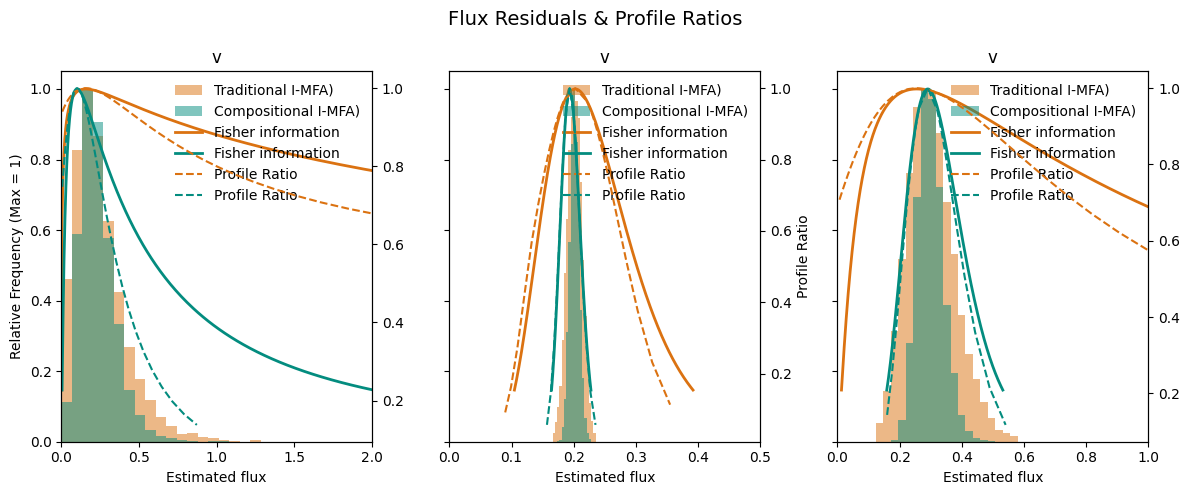

In [84]:
est_trad = estimated_fluxes_ref["trad"]
est_ilr = estimated_fluxes_ref["ilr"]

# Create 1x2 subplots just like your original setup
f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    est_trad_i = est_trad[:, i].flatten()
    est_ilr_i = est_ilr[:, i].flatten()
    
    xmin = np.quantile(np.concat([est_trad_i, est_ilr_i]), 0.001)
    xmax = np.quantile(np.concat([est_trad_i, est_ilr_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    
    # 1. Calculate peak-normalization weights for histograms
    counts_trad, _ = np.histogram(est_trad_i, bins=bins)
    counts_ilr, _ = np.histogram(est_ilr_i, bins=bins)
    
    weights_trad = np.ones_like(est_trad_i) / np.max(counts_trad)
    weights_ilr = np.ones_like(est_ilr_i) / np.max(counts_ilr)
    
    # 2. Plot the Histograms on the left y-axis (ax)
    h_trad = ax.hist(
        est_trad_i, 
        bins=bins,
        weights=weights_trad,
        color=TRAD,
        alpha=0.5,
        label=f"Traditional I-MFA)" 
    )
    h_ilr = ax.hist(
        est_ilr_i, 
        bins=bins,
        weights=weights_ilr,
        color=ILR,
        alpha=0.5,
        label=f"Compositional I-MFA)" 
    )
    
    # 3. Create a twin y-axis on the right side for the profile ratio line
    ax_twin = ax.twinx()
    
    # Extract the dynamic paths for the profile lines
    x_path_trad = result_trad.profile_result.get_profiler_result(i)["x_path"][i]
    ratio_path_trad = result_trad.profile_result.get_profiler_result(i)["ratio_path"]

    # Extract the dynamic paths for the profile lines
    x_path_ilr = result_ilr.profile_result.get_profiler_result(i)["x_path"][i]
    ratio_path_ilr = result_ilr.profile_result.get_profiler_result(i)["ratio_path"]
    
    # Plot the line (using a distinct color and style so it stands out)
    line = ax_twin.plot(x_path_trad, ratio_path_trad, color=TRAD, linestyle="--", label="Profile Ratio")
    line = ax_twin.plot(x_path_ilr, ratio_path_ilr, color=ILR, linestyle="--", label="Profile Ratio")
    
    x_trad, y_trad = fisher_interval(flux_est_trad[i], flux_sd_trad[i])
    ax.plot(x_trad, y_trad, label='Fisher information', color=TRAD, lw=2)
    
    x_ilr, y_ilr = fisher_interval(flux_est_ilr[i], flux_sd_ilr[i])
    ax.plot(x_ilr, y_ilr, label='Fisher information', color=ILR, lw=2)

    # 4. Formatting and Labels
    ax.set(title=f"v", xlabel="Estimated flux")
    
    # Combine legends from both axes so they appear in a single box
    lines_hist, labels_hist = ax.get_legend_handles_labels()
    lines_twin, labels_twin = ax_twin.get_legend_handles_labels()
    ax.legend(lines_hist + lines_twin, labels_hist + labels_twin, frameon=False, loc="upper right")
    
    # Set the right y-axis label only for the rightmost plot to keep it clean
    if i == 1:
        ax_twin.set_ylabel("Profile Ratio")
    else:
        # Optional: Link the right-hand y-axes if you want them to share limits
        pass 

# Set the left y-axis label for the histograms
axes[0].set_ylabel("Relative Frequency (Max = 1)")

axes[0].set_xlim(0,2)
axes[1].set_xlim(0,0.5)
axes[2].set_xlim(0,1)

f.suptitle("Flux Residuals & Profile Ratios", fontsize=14)
f.tight_layout()


In [5]:
import matplotlib.gridspec as gridspec

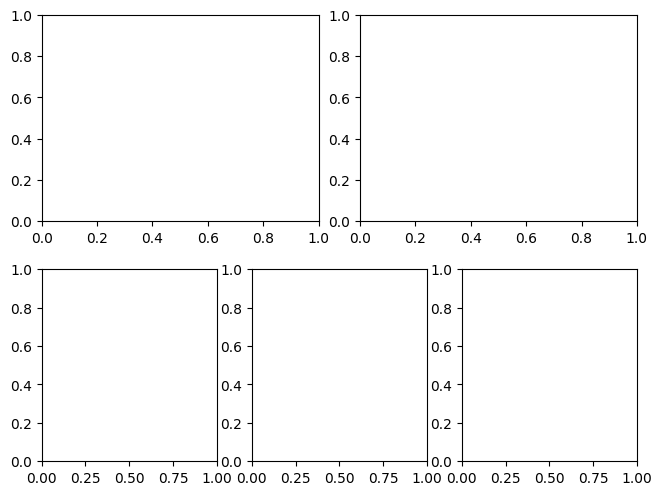

In [13]:
f = plt.figure()

gs1 = gridspec.GridSpec(1, 2)
gs1.update(left=0.05, right=0.98, top=0.98, bottom=0.55, wspace=0.15)
ax1 = plt.subplot(gs1[0])
ax2 = plt.subplot(gs1[1])

gs2 = gridspec.GridSpec(1, 3)
gs2.update(left=0.05, right=0.98, top=0.45, bottom=0.05, hspace=0.05)
ax3 = plt.subplot(gs2[0])
ax4 = plt.subplot(gs2[1])
ax5 = plt.subplot(gs2[2])
plt.show()